In [ ]:
import pandas as pd

df = pd.read_excel("COVID19_Data.xlsx")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (28240, 61)

First 5 Rows:


,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN



Column Names:
['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_boosters', 'new_vaccinations', 'new_vaccinati

In [ ]:
# Check missing values
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

print("Total Missing Values:", df.isnull().sum().sum())
display(missing_report)

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate country-date combinations
print(
    "Duplicate Country-Date Records:",
    df.duplicated(subset=["country", "date"]).sum()
)

Total Missing Values: 961867


,Missing_Count,Missing_Percentage
weekly_icu_admissions_per_million,28240,100.00
weekly_icu_admissions,28240,100.00
hosp_patients,28240,100.00
hosp_patients_per_million,28240,100.00
weekly_hosp_admissions,28240,100.00
weekly_hosp_admissions_per_million,28240,100.00
human_development_index,28240,100.00
excess_mortality_cumulative_absolute,27976,99.07
excess_mortality,27976,99.07
excess_mortality_cumulative,27976,99.07


Duplicate Rows: 0
Duplicate Country-Date Records: 0


In [ ]:
df_clean = df.copy()

# 1. Remove columns that are completely empty
empty_columns = df_clean.columns[
    df_clean.isnull().all()
].tolist()

df_clean = df_clean.drop(columns=empty_columns)

print("Completely empty columns removed:", empty_columns)

# 2. Fill missing continent labels using country records
if "continent" in df_clean.columns:
    continent_map = (
        df_clean.dropna(subset=["continent"])
        .groupby("country")["continent"]
        .first()
    )

    missing_continent = df_clean["continent"].isna()
    df_clean.loc[missing_continent, "continent"] = (
        df_clean.loc[missing_continent, "country"]
        .map(continent_map)
    )

# 3. Sort records by country and date
df_clean = df_clean.sort_values(
    ["country", "date"]
).reset_index(drop=True)


print("\nOriginal shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

display(df_clean.head())

Completely empty columns removed: ['hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'human_development_index']

Original shape: (28240, 61)
Cleaned shape: (28240, 54)
Remaining missing values: 764187
Duplicate rows: 0


,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,continent,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Asia,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Asia,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Asia,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,Asia,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,Asia,40578847,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35


In [ ]:
import numpy as np

df_clean = df_clean.sort_values(
    ["country", "date"]
).reset_index(drop=True)

# 1. 7-day rolling average of new cases
df_clean["new_cases_7day_avg"] = (
    df_clean.groupby("country")["new_cases"]
    .transform(lambda x: x.rolling(7, min_periods=7).mean())
)

# 2. Case Fatality Rate (percentage)
df_clean["case_fatality_rate"] = np.where(
    df_clean["total_cases"] > 0,
    (df_clean["total_deaths"] / df_clean["total_cases"]) * 100,
    np.nan
)

# 3. Doubling time (days)
cases_7_days_ago = (
    df_clean.groupby("country")["total_cases"].shift(7)
)

valid_growth = (
    (df_clean["total_cases"] > 0) &
    (cases_7_days_ago > 0) &
    (df_clean["total_cases"] > cases_7_days_ago)
)

df_clean["doubling_time_days"] = np.nan

df_clean.loc[valid_growth, "doubling_time_days"] = (
    7 * np.log(2) /
    np.log(
        df_clean.loc[valid_growth, "total_cases"] /
        cases_7_days_ago[valid_growth]
    )
)

display(
    df_clean[
        [
            "country",
            "date",
            "new_cases",
            "new_cases_7day_avg",
            "total_cases",
            "total_deaths",
            "case_fatality_rate",
            "doubling_time_days"
        ]
    ].tail(10)
)

,country,date,new_cases,new_cases_7day_avg,total_cases,total_deaths,case_fatality_rate,doubling_time_days
28230,Aruba,2024-01-11,0.0,0.0,44224.0,292.0,0.660275,NaN
28231,Aruba,2024-01-12,0.0,0.0,44224.0,292.0,0.660275,NaN
28232,Aruba,2024-01-13,0.0,0.0,44224.0,292.0,0.660275,NaN
28233,Aruba,2024-01-14,0.0,0.0,44224.0,292.0,0.660275,NaN
28234,Aruba,2024-01-15,0.0,0.0,44224.0,292.0,0.660275,NaN
28235,Aruba,2024-01-16,0.0,0.0,44224.0,292.0,0.660275,NaN
28236,Aruba,2024-01-17,0.0,0.0,44224.0,292.0,0.660275,NaN
28237,Aruba,2024-01-18,0.0,0.0,44224.0,292.0,0.660275,NaN
28238,Aruba,2024-01-19,0.0,0.0,44224.0,292.0,0.660275,NaN
28239,Aruba,2024-01-20,0.0,0.0,44224.0,292.0,0.660275,NaN


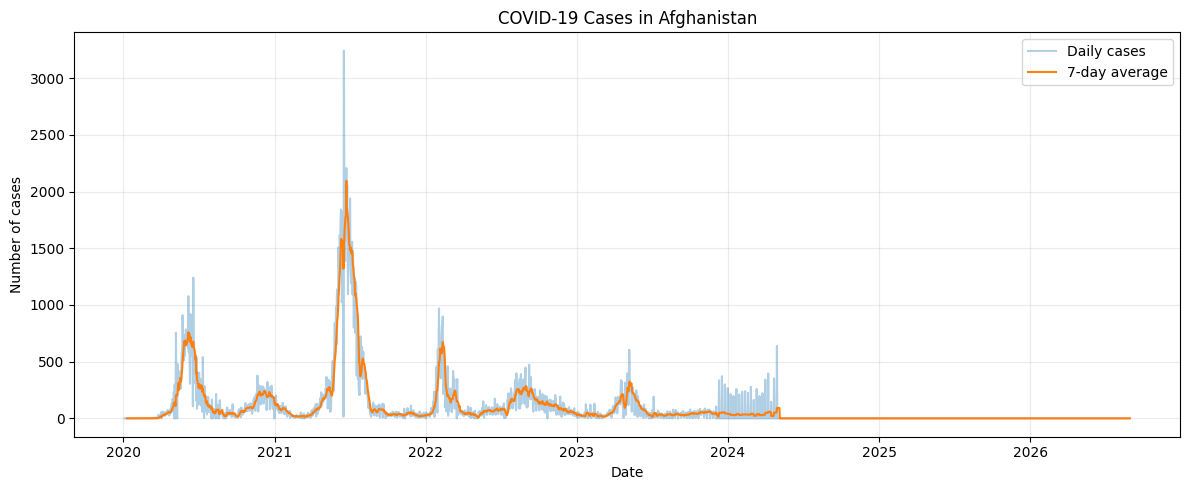

In [8]:
import matplotlib.pyplot as plt

country = "India"

if country not in df_clean["country"].unique():
    country = df_clean["country"].dropna().iloc[0]

data = df_clean[df_clean["country"] == country].copy()
data = data.sort_values("date")

# Daily cases and 7-day average
plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["new_cases"], alpha=0.35, label="Daily cases")
plt.plot(data["date"], data["new_cases_7day_avg"], label="7-day average")
plt.title(f"COVID-19 Cases in {country}")
plt.xlabel("Date")
plt.ylabel("Number of cases")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()




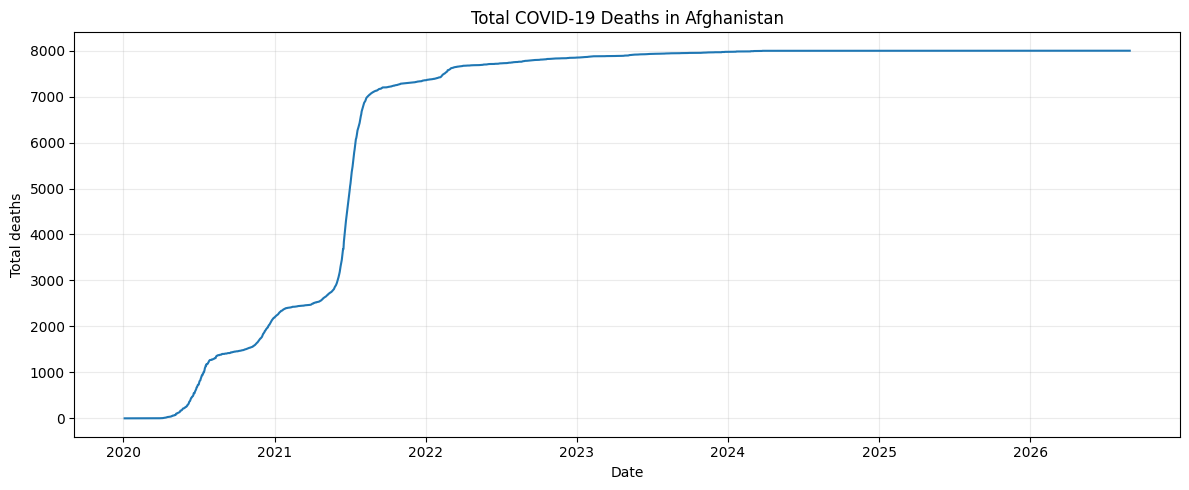

In [9]:
#  Total reported deaths over time
plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["total_deaths"])
plt.title(f"Total COVID-19 Deaths in {country}")
plt.xlabel("Date")
plt.ylabel("Total deaths")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

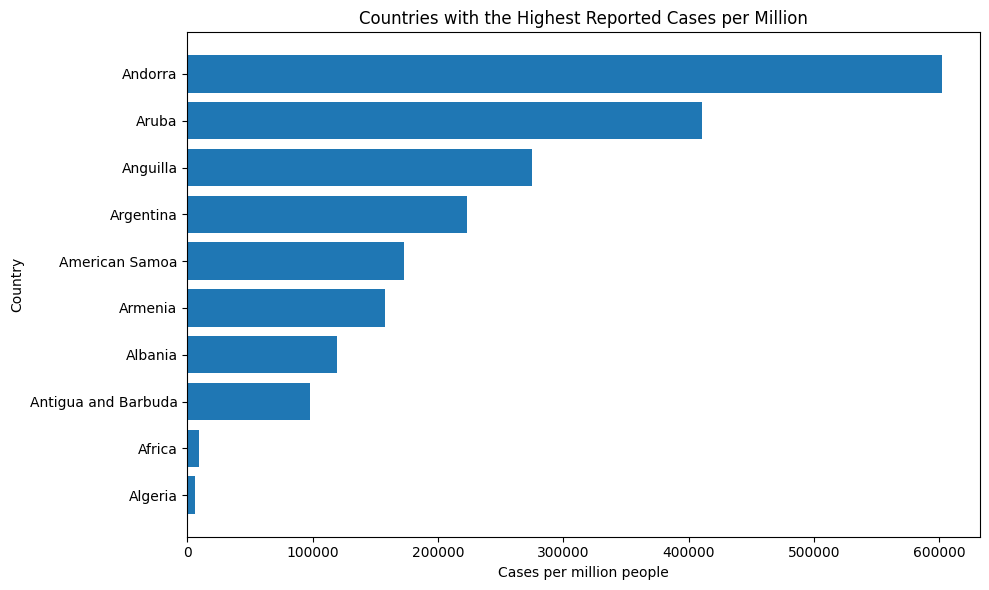

In [10]:
# Compare case rates across countries
latest = (
    df_clean.sort_values("date")
    .groupby("country", as_index=False)
    .tail(1)
    .dropna(subset=["total_cases_per_million"])
    .sort_values("total_cases_per_million", ascending=False)
    .head(10)
    .sort_values("total_cases_per_million")
)

plt.figure(figsize=(10, 6))
plt.barh(latest["country"], latest["total_cases_per_million"])
plt.title("Countries with the Highest Reported Cases per Million")
plt.xlabel("Cases per million people")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

